# BPSD — Behavioural-proxy correlation matrices (ML-1M · Gowalla · Yelp2018)

One notebook, three datasets. For each dataset it

1. **stages the raw data** into the shape the original pipeline expects (`ratings.dat` / `movies.dat`; 10-core filter for Gowalla and Yelp),
2. **rebuilds the exact train split** (`build_splits` / `read_splits` copied from the original notebooks, only parametrised so all three datasets can run in one session),
3. **builds the Stage-2 behavioural profiles** `q_u` (diversity, temporal stability, exploration, cross-category reach, loyalty) from the **train interactions + item metadata only**,
4. **checks your saved LightGCN checkpoint** against the rebuilt split (shapes, split fingerprint, and a re-evaluation of val/test NDCG),
5. **plots the Spearman correlation heatmaps** with the plotting code you supplied, one per dataset.

**About the checkpoints.** The five proxies do not depend on LightGCN: they are computed from train interactions, timestamps and item metadata (the original notebooks deliberately avoid the backbone's embeddings, so `q_u` does not re-encode the signal being debiased). What the checkpoint *does* tie to the proxies is the **split**: the train set determines the profiles, and a checkpoint trained on a different split would mean a different train set. Step 4 therefore re-evaluates the checkpoint on the rebuilt split. No LightGCN training happens here.

**Cells**
1. Config and paths
2. Data staging (raw → ml-1m-shaped files)
3. Splits (copied from the original notebooks)
4. Behavioural profiles (copied; item metadata is dataset-specific)
5. Build all three datasets
6. LightGCN checkpoint verification
7. Spearman heatmaps (your plotting code)
8. Optional combined figure

In [1]:
# ============================================================================
# CELL 1 — IMPORTS, PATHS, CONFIG
# ============================================================================
import os, sys, time, json, copy, random, collections, hashlib
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, entropy
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# ---- 1. WHERE THE RAW DATA LIVES (edit these) -------------------------------
ML1M_DIR    = '/kaggle/input/datasets/tejasdeshmukh001/movielens'            # contains ratings.dat + movies.dat
GOWALLA_DIR = '/kaggle/input/datasets/marquis03/gowalla'                                # contains loc-gowalla_totalCheckins.txt(.gz)
YELP_DIR    = '/kaggle/input/datasets/yelp-dataset/yelp-dataset'             # contains yelp_academic_dataset_{business,review}.json

# ---- 2. WHERE YOUR LIGHTGCN CHECKPOINTS ARE ---------------------------------
# Give the exact .pt path per dataset, or leave None to auto-search
# CKPT_SEARCH_DIRS for the usual file names (lightgcn-ml1m.pt, lightgcn-gowalla.pt,
# lightgcn-yelp2018.pt, ...).
CKPT_PATHS = {'ml-1m': None, 'gowalla': None, 'yelp2018': None}
CKPT_SEARCH_DIRS = ['/kaggle/input', '/kaggle/working']
VERIFY_BACKBONE = True        # False -> skip Cell 6 entirely (proxies don't need it)

RUN_DATASETS = ['ml-1m', 'gowalla', 'yelp2018']
REUSE_STAGED = True           # reuse gowalla_raw/ and yelp_raw/ from a previous run (they are deterministic)

DATASETS = {
    'ml-1m':    dict(display='MovieLens-1M', positive_threshold=4.0,
                     ckpt_names=['lightgcn-ml1m.pt', 'lightgcn-ml-1m.pt'],  ckpt_tokens=['ml1m', 'ml-1m', 'movielens']),
    'gowalla':  dict(display='Gowalla',      positive_threshold=1.0,
                     ckpt_names=['lightgcn-gowalla.pt'],                    ckpt_tokens=['gowalla']),
    'yelp2018': dict(display='Yelp2018',     positive_threshold=1.0,
                     ckpt_names=['lightgcn-yelp2018.pt'],                   ckpt_tokens=['yelp']),
}

# /kaggle/input is READ-ONLY -> every output goes to /kaggle/working.
OUT_ROOT = ('/kaggle/working/bpsd_out' if os.path.isdir('/kaggle/working')
            else os.environ.get('BPSD_OUT', './bpsd_out'))
CKPT_DIR = os.path.join(OUT_ROOT, 'checkpoints')
os.makedirs(OUT_ROOT, exist_ok=True)
print(f'[paths] out = {os.path.abspath(OUT_ROOT)}')

# ---- 3. PIPELINE CONSTANTS (identical to the original notebooks) ------------
SEED = 2020
TEST_HOLDOUT_PER_USER = 30
VAL_HOLDOUT_PER_USER  = 20
BALANCE_PER_ITEM      = None
STRICT_PPAC      = False
RECYCLE_DISCARDS = True
EVAL_ON_BALANCED = True
TOP_KS = [20, 50, 100]

MIN_USER_INTERACTIONS = 10    # 10-core filter, Gowalla + Yelp only
MIN_ITEM_INTERACTIONS = 10

# Stage-2 profile constants
N_CATEGORIES  = 20
CATEGORY_MODE = 'kmeans_genre'
WINDOW_DAYS   = 30
MIN_WINDOW_INTERACTIONS = 3
LOYALTY_WEIGHT = 'count'
DECONFOUND = False
PROXY_COLS = ['diversity', 'temporal_stability', 'exploration', 'cross_category', 'loyalty']

# LightGCN architecture (must match the checkpoints)
N_LAYERS = 3


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
    except ImportError:
        pass

[paths] out = /kaggle/working/bpsd_out


In [2]:
# ============================================================================
# CELL 2 — DATA STAGING  (raw -> ml-1m-shaped ratings.dat + movies.dat)
# Copied from the Gowalla/Yelp notebook's Cell 1. ML-1M needs no staging.
# ============================================================================
def _to_unix_seconds(s):
    """tz-aware datetime Series -> int64 unix seconds.
    The original used `.astype('int64') // 10**9`, which assumes nanosecond
    resolution; pandas >= 3 may parse to a coarser unit and that would silently
    give wrong timestamps. This form is resolution-independent and identical
    on older pandas."""
    return ((s - pd.Timestamp('1970-01-01', tz='UTC')) // pd.Timedelta(seconds=1)).astype('int64')


def _kcore_filter(edges, user_col='user', item_col='item'):
    """Iterative bipartite k-core filter, shared by both dataset loaders."""
    while True:
        uc = edges[user_col].value_counts()
        ic = edges[item_col].value_counts()
        keep_u = uc.index[uc >= MIN_USER_INTERACTIONS]
        keep_i = ic.index[ic >= MIN_ITEM_INTERACTIONS]
        filtered = edges[edges[user_col].isin(keep_u) & edges[item_col].isin(keep_i)]
        if len(filtered) == len(edges):
            return filtered
        edges = filtered


# ---------------------------------------------------------------------------
# ML-1M
# ---------------------------------------------------------------------------
def _find_ml1m_dir():
    base = ML1M_DIR or ''
    candidates = [
        base, os.path.join(base, 'ml-1m'), os.environ.get('ML1M_DIR'),
        '/kaggle/input/movielens-1m/ml-1m', '/kaggle/input/movielens-1m',
        './ml-1m', './data/ml-1m', '../ml-1m',
        os.path.expanduser('~/Documents/BPSD/ml-1m'),
    ]
    for c in candidates:
        if c and os.path.isfile(os.path.join(c, 'ratings.dat')) \
             and os.path.isfile(os.path.join(c, 'movies.dat')):
            return os.path.abspath(c)
    found = []
    if os.path.isdir('/kaggle/input'):
        for root, _, files in os.walk('/kaggle/input'):
            if 'ratings.dat' in files:
                found.append(root)
    raise FileNotFoundError(
        'Could not find ml-1m.\n'
        + (f'Folders under /kaggle/input containing ratings.dat:\n  '
           + '\n  '.join(found) + '\n\nSet ML1M_DIR to one of these.'
           if found else
           'Nothing under /kaggle/input has a ratings.dat -- add the dataset via '
           '"+ Add Input" in the right-hand panel first.'))


# ---------------------------------------------------------------------------
# GOWALLA
# ---------------------------------------------------------------------------
def _find_gowalla_checkins():
    candidates = [
        GOWALLA_DIR, os.environ.get('GOWALLA_DIR'),
        '/kaggle/input/gowalla', '/kaggle/input/gowalla-dataset',
        '/kaggle/input/loc-gowalla', '/kaggle/input/snap-gowalla',
        './gowalla', './data/gowalla', '../gowalla',
    ]
    names = ['loc-gowalla_totalCheckins.txt.gz', 'loc-gowalla_totalCheckins.txt',
             'Gowalla_totalCheckins.txt.gz', 'Gowalla_totalCheckins.txt']
    for c in candidates:
        if not c:
            continue
        for n in names:
            p = os.path.join(c, n)
            if os.path.isfile(p):
                return os.path.abspath(p)
    found = []
    if os.path.isdir('/kaggle/input'):
        for root, _, files in os.walk('/kaggle/input'):
            for f in files:
                fl = f.lower()
                if 'gowalla' in fl and 'checkin' in fl:
                    found.append(os.path.join(root, f))
    if found:
        return os.path.abspath(sorted(found)[0])
    raise FileNotFoundError(
        'Could not find loc-gowalla_totalCheckins.txt(.gz). Add the dataset via '
        '"+ Add Input" first, or set GOWALLA_DIR.')


def _prepare_gowalla_raw(checkins_path, out_root):
    """Raw check-ins -> ratings.dat (user::item::1.0::ts) + movies.dat (item::mean_lat::mean_lon).
    Repeat check-ins to the same location collapse to one positive, stamped at
    the EARLIEST check-in (first exposure)."""
    print(f'[gowalla] reading {checkins_path}')
    raw = pd.read_csv(checkins_path, sep='\t', header=None,
                      names=['user', 'time', 'lat', 'lon', 'item'],
                      dtype={'user': np.int64, 'lat': np.float64,
                             'lon': np.float64, 'item': np.int64})
    raw['ts'] = _to_unix_seconds(pd.to_datetime(raw['time'], format='%Y-%m-%dT%H:%M:%SZ', utc=True))
    print(f'[gowalla] raw check-ins: {len(raw):,} rows, '
          f'{raw["user"].nunique():,} users, {raw["item"].nunique():,} locations')

    coords = raw.groupby('item')[['lat', 'lon']].mean()
    edges = raw.groupby(['user', 'item'], as_index=False)['ts'].min()
    edges = _kcore_filter(edges)
    print(f'[gowalla] after {MIN_USER_INTERACTIONS}-core filtering: '
          f'{len(edges):,} interactions, {edges["user"].nunique():,} users, '
          f'{edges["item"].nunique():,} items')

    staging_dir = os.path.join(out_root, 'gowalla_raw')
    os.makedirs(staging_dir, exist_ok=True)

    items_sorted = np.sort(edges['item'].unique())
    with open(os.path.join(staging_dir, 'movies.dat'), 'w', encoding='latin-1') as fh:
        for it in items_sorted:
            lat, lon = coords.loc[it]
            fh.write(f'{it}::{lat:.6f}::{lon:.6f}\n')

    with open(os.path.join(staging_dir, 'ratings.dat'), 'w', encoding='latin-1') as fh:
        for u, i, t in zip(edges['user'].to_numpy(), edges['item'].to_numpy(),
                           edges['ts'].to_numpy()):
            fh.write(f'{u}::{i}::1.0::{t}\n')

    print(f'[gowalla] staged ml-1m-shaped files in {staging_dir}')
    return staging_dir


# ---------------------------------------------------------------------------
# YELP2018
# ---------------------------------------------------------------------------
def _find_yelp_files():
    candidates = [
        YELP_DIR, os.environ.get('YELP_DIR'),
        '/kaggle/input/yelp-dataset', '/kaggle/input/yelp',
        './yelp', './data/yelp', '../yelp',
    ]
    biz_names = ['yelp_academic_dataset_business.json', 'business.json']
    rev_names = ['yelp_academic_dataset_review.json', 'review.json']

    def _find(names):
        for c in candidates:
            if not c:
                continue
            for n in names:
                p = os.path.join(c, n)
                if os.path.isfile(p):
                    return os.path.abspath(p)
        if os.path.isdir('/kaggle/input'):
            for root, _, files in os.walk('/kaggle/input'):
                for f in files:
                    if f in names:
                        return os.path.abspath(os.path.join(root, f))
        return None

    biz, rev = _find(biz_names), _find(rev_names)
    missing = [n for n, p in [('business.json', biz), ('review.json', rev)] if p is None]
    if missing:
        raise FileNotFoundError(
            f'Could not find Yelp Open Dataset file(s): {missing}. Add the dataset '
            f'via "+ Add Input" first, or set YELP_DIR.')
    return biz, rev


def _prepare_yelp_raw(business_path, review_path, out_root):
    """Yelp Open Dataset JSON -> ratings.dat (user::item::stars::ts) + movies.dat (item::item::cat1|cat2|...).
    Every review is an implicit positive regardless of stars. Businesses with no
    `categories` are dropped up front (Stage 2 needs a category per item)."""
    print(f'[yelp] reading {business_path}')
    cat_of = {}
    with open(business_path, encoding='utf-8') as fh:
        for line in fh:
            d = json.loads(line)
            c = d.get('categories')
            if not c:
                continue
            toks = [t.strip().replace(':', ' ') for t in c.split(',') if t.strip()]
            if toks:
                cat_of[d['business_id']] = '|'.join(toks)
    print(f'[yelp] businesses with categories: {len(cat_of):,}')

    print(f'[yelp] reading {review_path} (this can take a few minutes)')
    users, items, stars, dates = [], [], [], []
    with open(review_path, encoding='utf-8') as fh:
        for line in fh:
            d = json.loads(line)
            bid = d['business_id']
            if bid not in cat_of:
                continue
            users.append(d['user_id']); items.append(bid)
            stars.append(int(d['stars'])); dates.append(d['date'])
    raw = pd.DataFrame({'user': users, 'item': items, 'stars': stars, 'date': dates})
    del users, items, stars, dates
    print(f'[yelp] raw reviews (categorised businesses only): {len(raw):,} rows, '
          f'{raw["user"].nunique():,} users, {raw["item"].nunique():,} businesses')

    raw['ts'] = _to_unix_seconds(pd.to_datetime(raw['date'], format='%Y-%m-%d %H:%M:%S', utc=True))

    # one row per (user, item): keep the EARLIEST review if a pair repeats (rare)
    edges = (raw.sort_values('ts')
             .groupby(['user', 'item'], as_index=False)
             .first()[['user', 'item', 'stars', 'ts']])
    del raw
    edges = _kcore_filter(edges)
    print(f'[yelp] after {MIN_USER_INTERACTIONS}-core filtering: '
          f'{len(edges):,} interactions, {edges["user"].nunique():,} users, '
          f'{edges["item"].nunique():,} items')

    staging_dir = os.path.join(out_root, 'yelp_raw')
    os.makedirs(staging_dir, exist_ok=True)

    user_id_map = {u: idx for idx, u in enumerate(sorted(edges['user'].unique()))}
    items_sorted = sorted(edges['item'].unique())
    with open(os.path.join(staging_dir, 'movies.dat'), 'w', encoding='utf-8') as fh:
        for b in items_sorted:
            fh.write(f'{b}::{b}::{cat_of[b]}\n')

    with open(os.path.join(staging_dir, 'ratings.dat'), 'w', encoding='utf-8') as fh:
        for u, i, s, t in zip(edges['user'].to_numpy(), edges['item'].to_numpy(),
                              edges['stars'].to_numpy(), edges['ts'].to_numpy()):
            fh.write(f'{user_id_map[u]}::{i}::{float(s):.1f}::{t}\n')

    print(f'[yelp] staged ml-1m-shaped files in {staging_dir}')
    return staging_dir


def stage_dataset(key):
    """Return a directory holding ml-1m-shaped ratings.dat + movies.dat for `key`."""
    if key == 'ml-1m':
        d = _find_ml1m_dir()
        print(f'[ml-1m] raw = {d}')
        return d
    sub = {'gowalla': 'gowalla_raw', 'yelp2018': 'yelp_raw'}[key]
    d = os.path.join(OUT_ROOT, sub)
    if REUSE_STAGED and all(os.path.isfile(os.path.join(d, f)) for f in ('ratings.dat', 'movies.dat')):
        print(f'[{key}] REUSE_STAGED: using existing {d}')
        return d
    if key == 'gowalla':
        return _prepare_gowalla_raw(_find_gowalla_checkins(), OUT_ROOT)
    biz, rev = _find_yelp_files()
    return _prepare_yelp_raw(biz, rev, OUT_ROOT)

In [3]:
# ============================================================================
# CELL 3 — SPLITS  (build_splits / read_splits / exclusion_for)
# Logic copied unchanged from the original notebooks; the only edit is that the
# former globals (RAW_DATA_DIR, WORKING_DIR, POSITIVE_RATING_THRESHOLD) are now
# arguments, so ML-1M, Gowalla and Yelp can run in the same session.
#
# The FULL split must be rebuilt (not just "train"): the final train set includes
# the balancing discards recycled from test/val (RECYCLE_DISCARDS), and which
# items are discarded depends on the balancing's RNG draws. Skipping any step
# would give a different train set than the one the checkpoint was trained on.
# ============================================================================
def build_splits(raw_dir, working_dir, positive_threshold):
    """Reproduce PPAC's split protocol, plus its balanced (intervened) test set."""
    os.makedirs(working_dir, exist_ok=True)
    rng = random.Random(SEED)
    by_user = collections.defaultdict(list)
    rating_of, ts_of = {}, {}

    with open(os.path.join(raw_dir, 'ratings.dat'), encoding='latin-1') as fh:
        for line in fh:
            u, i, r, t = line.strip().split('::')
            u, r, t = int(u), float(r), int(t)
            if r >= positive_threshold:
                by_user[u].append(i)
                rating_of[(u, i)] = r
                ts_of[(u, i)] = t

    train, val, test_pool = (collections.defaultdict(list) for _ in range(3))
    for u, items in by_user.items():
        items = list(items)
        rng.shuffle(items)
        need = TEST_HOLDOUT_PER_USER + (0 if STRICT_PPAC else VAL_HOLDOUT_PER_USER)
        if len(items) > need:
            test_pool[u] = items[:TEST_HOLDOUT_PER_USER]
            if not STRICT_PPAC:
                val[u] = items[TEST_HOLDOUT_PER_USER:need]
            train[u] = items[need:]
        else:
            train[u] = items

    def _balance(pool, quota=None):
        hits = collections.defaultdict(list)
        for u, items in pool.items():
            for i in items:
                hits[i].append(u)
        counts = np.array(sorted(len(v) for v in hits.values()))
        retained = counts[::-1] * (np.arange(len(counts)) + 1)
        q = int(quota) if quota else int(counts[::-1][retained.argmax()])
        out, n_items = collections.defaultdict(list), 0
        for i, users in hits.items():
            if len(users) >= q:
                n_items += 1
                for u in rng.sample(users, q):
                    out[u].append(i)
        return out, q, n_items

    balanced, quota, n_bal_items = _balance(test_pool, BALANCE_PER_ITEM)
    if STRICT_PPAC:
        bal_val, vq, vn = collections.defaultdict(list), 0, 0
    else:
        bal_val, vq, vn = _balance(val)

    print(f'[split] users={len(by_user)}')
    print(f'[split] raw test: {len(test_pool)} users, '
          f'{sum(map(len, test_pool.values()))} interactions')
    print(f'[split] balanced test: {len(balanced)} users, '
          f'{sum(map(len, balanced.values()))} interactions over '
          f'{n_bal_items} items @ {quota} each')
    if not STRICT_PPAC:
        print(f'[split] raw val: {len(val)} users, {sum(map(len, val.values()))} interactions')
        print(f'[split] balanced val: {len(bal_val)} users, '
              f'{sum(map(len, bal_val.values()))} interactions over {vn} items @ {vq} each')

    n_before = sum(map(len, train.values()))
    if RECYCLE_DISCARDS:
        n_rec = 0
        for pool, keepset in ((test_pool, balanced), (val, bal_val)):
            for u, items in pool.items():
                k = set(keepset.get(u, []))
                extra = [i for i in items if i not in k]
                train[u].extend(extra)
                n_rec += len(extra)
        print(f'[split] recycled {n_rec:,} discarded holdout interactions into train '
              f'(PPAC Sec 4.1); train {n_before:,} -> {sum(map(len, train.values())):,}')
    else:
        orphan = (sum(map(len, test_pool.values())) - sum(map(len, balanced.values()))
                  + sum(map(len, val.values())) - sum(map(len, bal_val.values())))
        print(f'[split] WARNING: {orphan:,} held-out positives are in NO split '
              f'(not trained on, not scored). This is not PPAC\'s protocol.')
    print(f'[split] final train_inter={sum(map(len, train.values()))}')

    def dump(name, recs):
        with open(os.path.join(working_dir, name), 'w', encoding='utf-8') as fh:
            for u, items in recs.items():
                for i in items:
                    fh.write(f'{u}::{i}::{rating_of[(u, i)]:.1f}::{ts_of[(u, i)]}\n')

    dump('ratings.train', train)
    dump('ratings.test', test_pool)
    dump('balance_ratings.test', balanced)
    if not STRICT_PPAC:
        dump('ratings.val', val)
        dump('balance_ratings.val', bal_val)


def read_splits(raw_dir, working_dir):
    """Load the splits and remap to compact 0-based ids."""
    item_map = {}
    with open(os.path.join(raw_dir, 'movies.dat'), encoding='latin-1') as fh:
        for idx, line in enumerate(fh):
            item_map[line.split('::')[0]] = idx

    def load(name):
        recs = collections.defaultdict(list)
        path = os.path.join(working_dir, name)
        if not os.path.exists(path):
            return recs
        with open(path, encoding='utf-8') as fh:
            for line in fh:
                u, i, _, _ = line.strip().split('::')
                recs[int(u)].append(item_map[i])
        return recs

    raw_train = load('ratings.train')
    user_map = {raw: new for new, raw in enumerate(sorted(raw_train))}
    train = collections.defaultdict(list, {user_map[u]: v for u, v in raw_train.items()})
    train_items = {i for v in train.values() for i in v}

    def remap(name, rankable_only):
        out = collections.defaultdict(list)
        for u, items in load(name).items():
            if u not in user_map:
                continue
            keep = items if not rankable_only else [i for i in items if i in train_items]
            if keep:
                out[user_map[u]] = keep
        return out

    test = remap('balance_ratings.test' if EVAL_ON_BALANCED else 'ratings.test', True)
    val  = remap('balance_ratings.val'  if EVAL_ON_BALANCED else 'ratings.val',  True)
    raw_val  = remap('ratings.val',  False)
    raw_test = remap('ratings.test', False)

    if STRICT_PPAC:
        val = test
    params = {'num_users': len(user_map), 'num_items': len(item_map)}
    return train, val, test, raw_val, raw_test, user_map, item_map, params


def exclusion_for(target, train_records, raw_val_records, raw_test_records):
    """Mask everything the user is known to like, except what we score now."""
    out = {}
    for u in train_records:
        seen = (set(train_records.get(u, []))
                | set(raw_val_records.get(u, []))
                | set(raw_test_records.get(u, [])))
        out[u] = list(seen - set(target.get(u, [])))
    return out


def load_dataset(key):
    """Stage -> split -> read. Returns a context dict for one dataset."""
    spec = DATASETS[key]
    print('\n' + '=' * 78 + f'\n{spec["display"]}\n' + '=' * 78)
    raw_dir = stage_dataset(key)
    working_dir = os.path.join(OUT_ROOT, 'dataset', key)
    set_seed(SEED)
    build_splits(raw_dir, working_dir, spec['positive_threshold'])
    (train, val, test, raw_val, raw_test, user_map, item_map, params) = read_splits(raw_dir, working_dir)
    ctx = dict(key=key, display=spec['display'], raw_dir=raw_dir, working_dir=working_dir,
               train_records=train, val_records=val, test_records=test,
               raw_val_records=raw_val, raw_test_records=raw_test,
               user_map=user_map, item_map=item_map,
               num_users=params['num_users'], num_items=params['num_items'])
    print(f'[data] users={ctx["num_users"]} items={ctx["num_items"]} '
          f'train={sum(map(len, train.values()))} '
          f'val_users={len(val)} test_users={len(test)}')
    return ctx

In [4]:
# ============================================================================
# CELL 4 — STAGE 2: BEHAVIOURAL PROFILES (§7)
# Copied from the original notebooks. Categories and content vectors come from
# item METADATA, never from KMeans on LightGCN embeddings. Only change vs. the
# originals: functions take (raw_dir, dataset key, ctx) instead of reading
# globals, and results are saved per dataset.
#   * ml-1m / yelp2018 : movies.dat = item::<unused>::g1|g2|...  (genre-style)
#   * gowalla          : movies.dat = item::mean_lat::mean_lon   (coords-style)
# ============================================================================
def _build_item_metadata_genre_style(raw_dir, item_map, n_categories):
    genres_of, vocab = {}, {}
    with open(os.path.join(raw_dir, 'movies.dat'), encoding='latin-1') as fh:
        for line in fh:
            mid, _, gstr = line.strip().split('::')
            gs = gstr.split('|')
            genres_of[item_map[mid]] = gs
            for g in gs:
                vocab.setdefault(g, len(vocab))

    content = np.zeros((len(item_map), len(vocab)), dtype=np.float32)
    for i, gs in genres_of.items():
        for g in gs:
            content[i, vocab[g]] = 1.0
    content /= np.maximum(np.linalg.norm(content, axis=1, keepdims=True), 1e-9)

    if CATEGORY_MODE == 'primary_genre':
        freq = collections.Counter(g for gs in genres_of.values() for g in gs)
        cat = np.array([vocab[min(genres_of[i], key=lambda g: freq[g])]
                        for i in range(len(item_map))], dtype=np.int64)
    else:
        km = KMeans(n_clusters=min(n_categories, len(item_map)), random_state=42, n_init=10)
        cat = km.fit_predict(content).astype(np.int64)
    return content, cat, int(cat.max()) + 1


def _build_item_metadata_coords_style(raw_dir, item_map, n_categories):
    """gowalla: z-scored coords -> KMeans (category); z-scored + L2-normalised
    coords -> content (so 1 - cos is a bounded directional dissimilarity)."""
    coords_of = {}
    with open(os.path.join(raw_dir, 'movies.dat'), encoding='latin-1') as fh:
        for line in fh:
            loc_id, lat_s, lon_s = line.strip().split('::')
            coords_of[item_map[loc_id]] = (float(lat_s), float(lon_s))

    coords = np.zeros((len(item_map), 2), dtype=np.float64)
    for i, (lat, lon) in coords_of.items():
        coords[i] = (lat, lon)

    mu, sd = coords.mean(0), coords.std(0)
    sd = np.where(sd < 1e-9, 1.0, sd)
    standardized = ((coords - mu) / sd).astype(np.float32)

    content = standardized.copy()
    content /= np.maximum(np.linalg.norm(content, axis=1, keepdims=True), 1e-9)

    if CATEGORY_MODE == 'primary_genre':
        print('[stage2] CATEGORY_MODE="primary_genre" has no Gowalla analogue; '
              'falling back to KMeans over standardized coordinates.')
    km = KMeans(n_clusters=min(n_categories, len(item_map)), random_state=42, n_init=10)
    cat = km.fit_predict(standardized).astype(np.int64)
    return content, cat, int(cat.max()) + 1


def build_item_metadata(raw_dir, item_map, dataset_key, n_categories=N_CATEGORIES):
    if dataset_key == 'gowalla':
        return _build_item_metadata_coords_style(raw_dir, item_map, n_categories)
    return _build_item_metadata_genre_style(raw_dir, item_map, n_categories)


def user_profiles(interactions, content, category, n_cats):
    """§7.2-7.7. interactions: DataFrame[user, item, rating, timestamp]."""
    recs = []
    for uid, grp in interactions.groupby('user', sort=True):
        items = grp['item'].to_numpy()
        if len(items) < 2:
            continue
        cats = category[items]

        # §7.2 diversity: mean pairwise (1 - cos) over CONTENT vectors
        V = content[items]
        S = V @ V.T
        iu = np.triu_indices(len(items), k=1)
        diversity = float((1.0 - S[iu]).mean())

        # §7.5 cross-category reach: Shannon entropy of P(c|u)
        counts = np.bincount(cats, minlength=n_cats).astype(np.float64)
        probs = counts[counts > 0] / counts.sum()
        cross = float(entropy(probs))

        # §7.4 exploration: fraction of items outside the user's top-3 categories
        top3 = set(np.argsort(-counts)[:3].tolist())
        exploration = float(np.mean([c not in top3 for c in cats]))

        # §7.6 loyalty
        w = (grp['rating'].to_numpy(np.float64) if LOYALTY_WEIGHT == 'rating'
             else np.ones(len(items)))
        agg = np.bincount(pd.factorize(items)[0], weights=w)
        loyalty = float(((agg / agg.sum()) ** 2).sum())

        # §7.3 temporal stability: Spearman between the FULL n_cats-length category
        # histograms of consecutive TIME windows.
        ts = grp['timestamp'].to_numpy(np.int64)
        order = np.argsort(ts)
        ts_o, cats_o = ts[order], cats[order]
        span = WINDOW_DAYS * 86400
        wins, cur, start = [], [], ts_o[0]
        for t, c in zip(ts_o, cats_o):
            if t - start > span and len(cur) >= MIN_WINDOW_INTERACTIONS:
                wins.append(cur); cur, start = [], t
            cur.append(c)
        if len(cur) >= MIN_WINDOW_INTERACTIONS:
            wins.append(cur)
        if len(wins) < 2:                       # fallback: equal-count halves
            half = len(cats_o) // 2
            wins = [cats_o[:half].tolist(), cats_o[half:].tolist()] if half >= 1 else []
        rhos = []
        for a, b in zip(wins[:-1], wins[1:]):
            ha = np.bincount(np.asarray(a), minlength=n_cats).astype(np.float64)
            hb = np.bincount(np.asarray(b), minlength=n_cats).astype(np.float64)
            if ha.std() > 0 and hb.std() > 0:
                rho = spearmanr(ha, hb).statistic
                if not np.isnan(rho):
                    rhos.append(rho)
        temporal = float(np.mean(rhos)) if rhos else 0.0

        recs.append({'user': uid, 'diversity': diversity, 'temporal_stability': temporal,
                     'exploration': exploration, 'cross_category': cross,
                     'loyalty': loyalty, '_degree': len(items)})

    df = pd.DataFrame(recs)
    for c in PROXY_COLS:                                       # §7.7 min-max
        lo, hi = df[c].min(), df[c].max()
        df[c] = (df[c] - lo) / (hi - lo + 1e-8)
    if DECONFOUND:                                             # §7.8 -- OFF
        bins = pd.qcut(df['_degree'], q=10, labels=False, duplicates='drop')
        for c in PROXY_COLS:
            df[c] = df[c] - df.groupby(bins)[c].transform('mean')
    return df.drop(columns=['_degree'])


def build_profiles(ctx):
    """Stage 2 for one dataset. Returns (q_u_df, q_i_df, interactions_df)."""
    raw_dir, key = ctx['raw_dir'], ctx['key']
    item_map, user_map, train_records = ctx['item_map'], ctx['user_map'], ctx['train_records']
    num_items = ctx['num_items']

    inv_item = {v: k for k, v in item_map.items()}
    inv_user = {v: k for k, v in user_map.items()}
    ts_lookup = {}
    with open(os.path.join(raw_dir, 'ratings.dat'), encoding='latin-1') as fh:
        for line in fh:
            u, i, r, t = line.strip().split('::')
            ts_lookup[(int(u), i)] = (float(r), int(t))

    inter = []
    for u, items in train_records.items():          # TRAIN ONLY -- no leakage
        ru = inv_user[u]
        for i in items:
            r, t = ts_lookup[(ru, inv_item[i])]
            inter.append((u, i, r, t))
    df = pd.DataFrame(inter, columns=['user', 'item', 'rating', 'timestamp'])
    del ts_lookup

    content, category, n_cats = build_item_metadata(raw_dir, item_map, key)
    q_u_df = user_profiles(df, content, category, n_cats)
    print(f'[stage2:{key}] q_u for {len(q_u_df)}/{ctx["num_users"]} users, {n_cats} categories')

    # §7.9 q_i = mean of q_u over N(i); unseen items get the COLUMN MEAN, not 0
    q_i_df = (df[['user', 'item']].merge(q_u_df, on='user', how='inner')
              .groupby('item')[PROXY_COLS].mean().reset_index())
    q_i_df = pd.DataFrame({'item': np.arange(num_items)}).merge(q_i_df, on='item', how='left')
    q_i_df[PROXY_COLS] = q_i_df[PROXY_COLS].fillna(q_i_df[PROXY_COLS].mean())

    q_u_df.to_csv(os.path.join(OUT_ROOT, f'q_u_profiles_{key}.csv'), index=False)
    q_i_df.to_csv(os.path.join(OUT_ROOT, f'q_i_profiles_{key}.csv'), index=False)
    return q_u_df, q_i_df, df

In [5]:
# ============================================================================
# CELL 5 — BUILD ALL THREE DATASETS  (staging + split + profiles)
# Yelp staging parses review.json (several minutes) the first time; later runs
# reuse yelp_raw/ if REUSE_STAGED is True.
# ============================================================================
CTX = {}            # key -> context dict (splits, maps)
PROFILES = {}       # key -> (q_u_df, q_i_df, interactions_df)
proxy_data = {}     # DISPLAY NAME -> DataFrame[PROXY_COLS]  (what Cell 7 plots)

for key in RUN_DATASETS:
    t0 = time.time()
    CTX[key] = load_dataset(key)
    PROFILES[key] = build_profiles(CTX[key])
    q_u_df = PROFILES[key][0]
    # user-level profiles of users that HAVE one (>= 2 train items). We do NOT use the
    # mean-filled q_u tensor here: filled rows would be identical copies of the column
    # mean and add artificial ties to the rank correlation.
    proxy_data[CTX[key]['display']] = q_u_df[PROXY_COLS].reset_index(drop=True)
    print(f'[{key}] done in {time.time() - t0:.0f}s\n')

print('Users per dataset (with a behavioural profile):')
for name, d in proxy_data.items():
    nan_cols = d.columns[d.isna().any()].tolist()
    const_cols = [c for c in d.columns if d[c].nunique() <= 1]
    print(f'  {name:<14} n={len(d):>7,}   NaN cols: {nan_cols or "none"}   constant cols: {const_cols or "none"}')
display(pd.concat({n: d.describe().loc[['mean', 'std', 'min', 'max']].round(3) for n, d in proxy_data.items()}))


MovieLens-1M
[ml-1m] raw = /kaggle/input/datasets/tejasdeshmukh001/movielens
[split] users=6038
[split] raw test: 3329 users, 99870 interactions
[split] balanced test: 3329 users, 29882 interactions over 446 items @ 67 each
[split] raw val: 3329 users, 66580 interactions
[split] balanced val: 3325 users, 19932 interactions over 453 items @ 44 each
[split] recycled 116,636 discarded holdout interactions into train (PPAC Sec 4.1); train 408,831 -> 525,467
[split] final train_inter=525467
[data] users=6038 items=3883 train=525467 val_users=3325 test_users=3329
[stage2:ml-1m] q_u for 6037/6038 users, 20 categories
[ml-1m] done in 27s


Gowalla
[gowalla] reading /kaggle/input/datasets/marquis03/gowalla/Gowalla_totalCheckins.txt
[gowalla] raw check-ins: 6,442,892 rows, 107,092 users, 1,280,969 locations
[gowalla] after 10-core filtering: 1,027,464 interactions, 29,858 users, 40,988 items
[gowalla] staged ml-1m-shaped files in /kaggle/working/bpsd_out/gowalla_raw
[split] users=29858
[split] 

diversity  temporal_stability  exploration  cross_category  \
MovieLens-1M mean      0.618               0.591        0.608           0.724   
             std       0.128               0.156        0.184           0.155   
             min       0.000               0.000        0.000           0.000   
             max       1.000               1.000        1.000           1.000   
Gowalla      mean      0.084               0.849        0.032           0.181   
             std       0.163               0.174        0.097           0.187   
             min       0.000               0.000        0.000           0.000   
             max       1.000               1.000        1.000           1.000   
Yelp2018     mean      0.695               0.479        0.517           0.672   
             std       0.099               0.131        0.156           0.110   
             min       0.000               0.000        0.000           0.000   
             max       1.000               1.000        1.000           1.000   

                   loyalty  
MovieLens-1M mean    0.053  
             std     0.052  
             min     0.000  
             max     1.000  
Gowalla      mean    0.514  
             std     0.271  
             min     0.000  
             max     1.000  
Yelp2018     mean    0.606  
             std     0.276  
             min     0.000  
             max     1.000

In [6]:
# ============================================================================
# CELL 6 — LIGHTGCN CHECKPOINT VERIFICATION  (no training)
# For each dataset: find the checkpoint, load it, and confirm it belongs to the
# split rebuilt above. Checks, strongest first:
#   1. split fingerprint stored in the checkpoint == fingerprint of rebuilt train
#      (only checkpoints from the resumable Gowalla/Yelp notebook store it)
#   2. val NDCG@50 re-computed here == the 'best' value stored in the checkpoint
#      (same source)
#   3. embedding shapes == (num_users, dim) / (num_items, dim)   (always)
#   4. test/val Recall & NDCG @50 printed so you can compare with your logs
#      (the only content check available for legacy ML-1M-style checkpoints,
#      which store just {'epoch', 'model_state_dict'})
# The proxies in Cell 5 are already built and do not depend on this cell's outcome.
# ============================================================================
def _train_fingerprint(train_recs, num_items):
    keys = np.sort(np.concatenate([np.asarray(v, dtype=np.int64) + np.int64(u) * num_items
                                   for u, v in train_recs.items() if len(v)]))
    return hashlib.md5(keys.tobytes()).hexdigest()


_PT_INDEX = None
def _find_ckpt(key):
    """Explicit CKPT_PATHS entry > exact file name > token match (never '-resume')."""
    global _PT_INDEX
    explicit = CKPT_PATHS.get(key)
    if explicit:
        if not os.path.isfile(explicit):
            raise FileNotFoundError(f'CKPT_PATHS[{key!r}] = {explicit} does not exist')
        return explicit
    if _PT_INDEX is None:
        _PT_INDEX = []
        for d in [CKPT_DIR] + list(CKPT_SEARCH_DIRS):
            if d and os.path.isdir(d):
                for root, _, files in os.walk(d):
                    _PT_INDEX += [os.path.join(root, f) for f in files if f.endswith('.pt')]
    spec = DATASETS[key]
    for p in _PT_INDEX:
        if os.path.basename(p) in spec['ckpt_names']:
            return p
    for p in _PT_INDEX:
        b = os.path.basename(p).lower()
        if 'resume' not in b and any(t in b for t in spec['ckpt_tokens']):
            return p
    return None


def _extract_state(ck):
    if isinstance(ck, dict):
        for k in ('best_state', 'model_state_dict', 'model_state', 'state_dict'):
            if k in ck and isinstance(ck[k], dict):
                return ck[k], k
        if 'user_embedding.weight' in ck:
            return ck, '<raw state_dict>'
    return None, None


def _backbone_eval(torch, e_u, e_i, eval_recs, excl, ks=(50,)):
    """Recall/NDCG of dot-product ranking, with every known positive masked."""
    users = sorted(u for u, v in eval_recs.items() if v)
    max_k = max(ks)
    ranked = []
    with torch.no_grad():
        for s in range(0, len(users), 512):
            b = users[s:s + 512]
            scores = e_u[b] @ e_i.T
            rows = np.concatenate([np.full(len(excl.get(u, [])), r, dtype=np.int64) for r, u in enumerate(b)])
            cols = np.concatenate([np.asarray(excl.get(u, []), dtype=np.int64) for u in b])
            if rows.size:
                scores[torch.from_numpy(rows).to(scores.device),
                       torch.from_numpy(cols).to(scores.device)] = -torch.inf
            ranked.append(torch.topk(scores, k=max_k, dim=1).indices.cpu().numpy())
    ranked = np.concatenate(ranked, 0)
    truth = [eval_recs[u] for u in users]
    out = {}
    for k in ks:
        disc = 1.0 / np.log2(np.arange(2, k + 2))
        rec, ndcg = [], []
        for t, row_ in zip(truth, ranked):
            ts = set(t)
            hits = np.fromiter((i in ts for i in row_[:k]), np.float32, k)
            rec.append(hits.sum() / len(ts))
            idcg = disc[:min(len(ts), k)].sum()
            ndcg.append(float((hits * disc).sum()) / idcg if idcg > 0 else 0.0)
        out[k] = (float(np.mean(rec)), float(np.mean(ndcg)))
    return out


def verify_with_backbone(ctx, path):
    import torch
    dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    ck = torch.load(path, map_location='cpu', weights_only=False)   # your own file
    state, state_key = _extract_state(ck)
    if state is None:
        raise RuntimeError(f'no model weights found in {path} (keys: {list(ck)[:8] if isinstance(ck, dict) else type(ck)})')
    nu, ni = ctx['num_users'], ctx['num_items']
    Wu, Wi = state['user_embedding.weight'], state['item_embedding.weight']
    res = dict(path=path, state_key=state_key, dim=int(Wu.shape[1]), problems=[])

    if tuple(Wu.shape) != (nu, Wu.shape[1]) or tuple(Wi.shape) != (ni, Wi.shape[1]):
        res['problems'].append(f'shape mismatch: ckpt users/items = {Wu.shape[0]}/{Wi.shape[0]}, '
                               f'rebuilt split = {nu}/{ni}')
        res['verdict'] = 'MISMATCH'
        return res

    fp_now = _train_fingerprint(ctx['train_records'], ni)
    fp_ck = ck.get('fingerprint') if isinstance(ck, dict) else None
    res['fingerprint'] = ('not stored' if fp_ck is None else ('match' if fp_ck == fp_now else 'MISMATCH'))
    if fp_ck is not None and fp_ck != fp_now:
        res['problems'].append('train fingerprint differs: checkpoint was trained on a different split')

    # rebuild adjacency from the rebuilt train set and propagate (LightGCN readout)
    us, it = [], []
    for u, items in ctx['train_records'].items():
        us.extend([u] * len(items)); it.extend([i + nu for i in items])
    us = torch.tensor(us, dtype=torch.long); it = torch.tensor(it, dtype=torch.long)
    n = nu + ni
    src, dst = torch.cat([us, it]), torch.cat([it, us])
    deg = torch.zeros(n).scatter_add_(0, dst, torch.ones(dst.numel()))
    dis = deg.clamp(min=1.0).pow(-0.5)
    adj = torch.sparse_coo_tensor(torch.stack([dst, src]), dis[dst] * dis[src], (n, n)).coalesce().to(dev)
    with torch.no_grad():
        x = torch.cat([Wu, Wi], 0).float().to(dev)
        layers = [x]
        for _ in range(N_LAYERS):
            x = torch.sparse.mm(adj, x); layers.append(x)
        out = torch.stack(layers, 1).mean(1)
        e_u, e_i = out[:nu], out[nu:]

    excl_val  = exclusion_for(ctx['val_records'],  ctx['train_records'], ctx['raw_val_records'], ctx['raw_test_records'])
    excl_test = exclusion_for(ctx['test_records'], ctx['train_records'], ctx['raw_val_records'], ctx['raw_test_records'])
    mv = _backbone_eval(torch, e_u, e_i, ctx['val_records'],  excl_val)
    mt = _backbone_eval(torch, e_u, e_i, ctx['test_records'], excl_test)
    res['val_recall50'], res['val_ndcg50'] = mv[50]
    res['test_recall50'], res['test_ndcg50'] = mt[50]

    best = ck.get('best') if isinstance(ck, dict) else None
    if best is not None and not STRICT_PPAC:
        res['stored_val_ndcg50'] = float(best)
        if abs(float(best) - res['val_ndcg50']) > 2e-3:
            res['problems'].append(f'val NDCG@50 {res["val_ndcg50"]:.4f} != stored {float(best):.4f}')

    if res['problems']:
        res['verdict'] = 'MISMATCH'
    elif fp_ck is not None or best is not None:
        res['verdict'] = 'VERIFIED'
    else:
        res['verdict'] = 'SHAPES OK (legacy checkpoint: compare NDCG with your log)'
    del adj, x, layers, out, e_u, e_i
    if dev.type == 'cuda':
        torch.cuda.empty_cache()
    return res


VERIFY = {}
if VERIFY_BACKBONE:
    for key in RUN_DATASETS:
        name = CTX[key]['display']
        try:
            path = _find_ckpt(key)
            if path is None:
                VERIFY[key] = dict(verdict='NO CHECKPOINT FOUND',
                                   problems=[f'set CKPT_PATHS[{key!r}] or add the folder to CKPT_SEARCH_DIRS'])
            else:
                VERIFY[key] = verify_with_backbone(CTX[key], path)
        except Exception as e:                        # never block the heatmaps
            VERIFY[key] = dict(verdict=f'ERROR: {type(e).__name__}', problems=[str(e)])
        v = VERIFY[key]
        print(f'\n[{name}] {v["verdict"]}')
        if 'path' in v:
            print(f'  file        : {v["path"]}  ({v["state_key"]}, dim={v["dim"]})')
        if 'fingerprint' in v:
            print(f'  fingerprint : {v["fingerprint"]}')
        if 'val_ndcg50' in v:
            stored = f'   (stored in ckpt: {v["stored_val_ndcg50"]:.4f})' if 'stored_val_ndcg50' in v else ''
            print(f'  val  @50    : Recall {v["val_recall50"]:.4f}  NDCG {v["val_ndcg50"]:.4f}{stored}')
            print(f'  test @50    : Recall {v["test_recall50"]:.4f}  NDCG {v["test_ndcg50"]:.4f}')
        for p in v.get('problems', []):
            print(f'  !! {p}')
    bad = [k for k, v in VERIFY.items() if v['verdict'].startswith(('MISMATCH', 'ERROR'))]
    if bad:
        print(f'\n!!! Checkpoint/split problems for: {bad}. The heatmaps below are still computed from the '
              f'rebuilt train split; do not pair them with these checkpoints until this is resolved.')
else:
    print('VERIFY_BACKBONE = False -> skipped')

/tmp/ipykernel_23/1248873297.py:120: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  adj = torch.sparse_coo_tensor(torch.stack([dst, src]), dis[dst] * dis[src], (n, n)).coalesce().to(dev)



[MovieLens-1M] MISMATCH
  file        : /kaggle/input/models/tejasdeshmukh001/lightgcn-ml1m-pt/pytorch/default/1/lightgcn-ml1m.pt  (model_state_dict, dim=64)
  fingerprint : MISMATCH
  val  @50    : Recall 0.4444  NDCG 0.2595
  test @50    : Recall 0.4441  NDCG 0.3001
  !! train fingerprint differs: checkpoint was trained on a different split

[Gowalla] NO CHECKPOINT FOUND
  !! set CKPT_PATHS['gowalla'] or add the folder to CKPT_SEARCH_DIRS

[Yelp2018] VERIFIED
  file        : /kaggle/input/models/tejasdeshmukh001/lightgcn-yelp2018-pt/other/default/1/lightgcn-yelp2018.pt  (best_state, dim=64)
  fingerprint : match
  val  @50    : Recall 0.1174  NDCG 0.0613   (stored in ckpt: 0.0613)
  test @50    : Recall 0.1153  NDCG 0.0686

!!! Checkpoint/split problems for: ['ml-1m']. The heatmaps below are still computed from the rebuilt train split; do not pair them with these checkpoints until this is resolved.


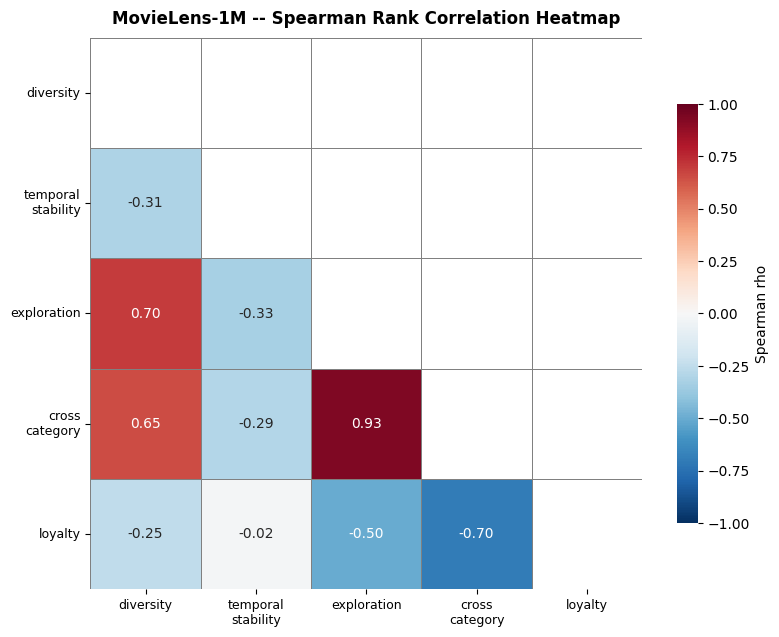


MovieLens-1M -- Spearman Correlation Matrix:


,diversity,temporal_stability,exploration,cross_category,loyalty
diversity,1.000,-0.307,0.697,0.653,-0.251
temporal_stability,-0.307,1.000,-0.328,-0.293,-0.017
exploration,0.697,-0.328,1.000,0.933,-0.503
cross_category,0.653,-0.293,0.933,1.000,-0.697
loyalty,-0.251,-0.017,-0.503,-0.697,1.000


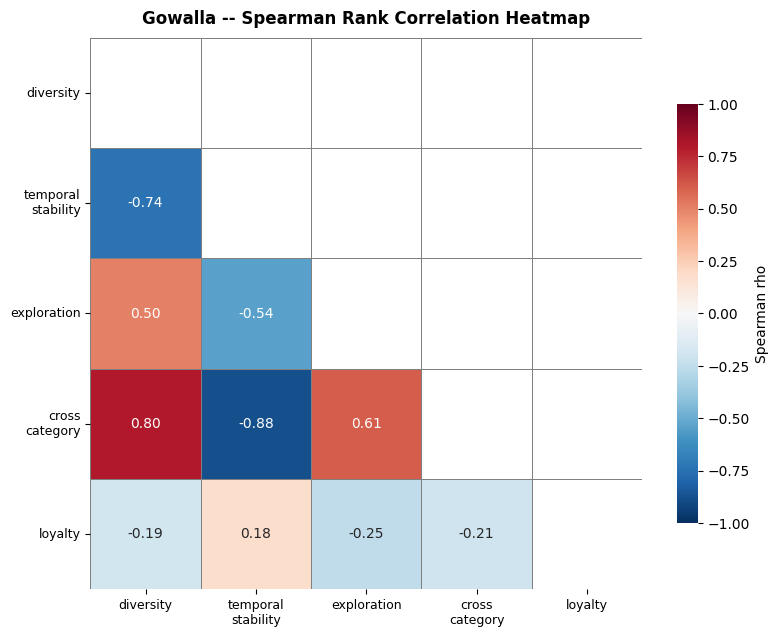


Gowalla -- Spearman Correlation Matrix:


,diversity,temporal_stability,exploration,cross_category,loyalty
diversity,1.000,-0.741,0.500,0.799,-0.194
temporal_stability,-0.741,1.000,-0.543,-0.876,0.179
exploration,0.500,-0.543,1.000,0.609,-0.254
cross_category,0.799,-0.876,0.609,1.000,-0.210
loyalty,-0.194,0.179,-0.254,-0.210,1.000


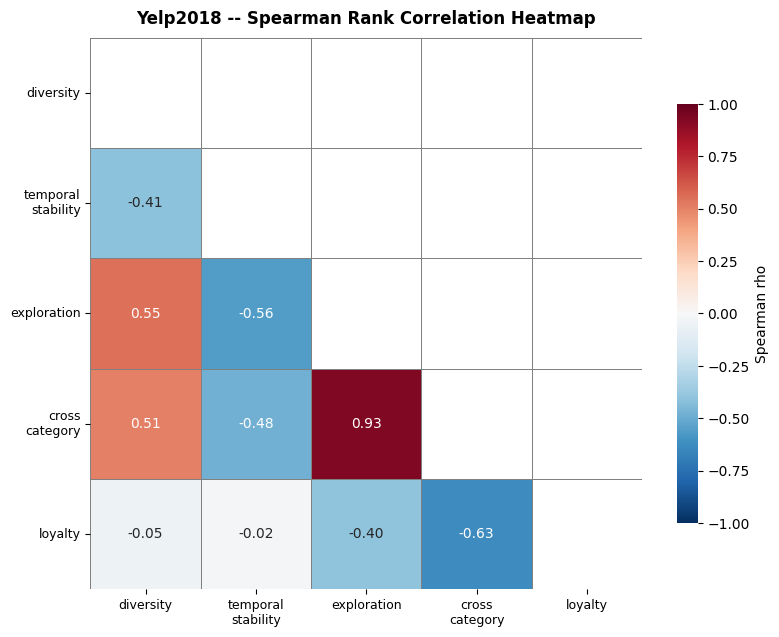


Yelp2018 -- Spearman Correlation Matrix:


,diversity,temporal_stability,exploration,cross_category,loyalty
diversity,1.000,-0.414,0.554,0.507,-0.050
temporal_stability,-0.414,1.000,-0.562,-0.478,-0.022
exploration,0.554,-0.562,1.000,0.927,-0.401
cross_category,0.507,-0.478,0.927,1.000,-0.629
loyalty,-0.050,-0.022,-0.401,-0.629,1.000


In [7]:
# ============================================================================
# CELL 7 — SPEARMAN HEATMAPS  (your plotting code, unchanged)
# `CMAP_DIV` was not in the snippet you sent; set to a standard diverging map.
# Change it here if your paper uses another one.
# ============================================================================
CMAP_DIV = 'RdBu_r'


def plot_corr_heatmap(corr_matrix, title, ax, vmin=-1, vmax=1,
                      annot=True, fmt='.2f', cmap=CMAP_DIV, mask_upper=True):
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) if mask_upper else None
    sns.heatmap(
        corr_matrix, ax=ax, mask=mask,
        annot=annot, fmt=fmt, cmap=cmap,
        vmin=vmin, vmax=vmax,
        linewidths=0.5, linecolor='grey', square=True,
        cbar_kws={'shrink': 0.75, 'label': 'Spearman rho'},
    )
    labels = [l.replace('_', '\n') for l in corr_matrix.columns]
    ax.set_xticklabels(labels, rotation=0, ha='center', fontsize=9)
    ax.set_yticklabels(labels, rotation=0, fontsize=9)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)

corr_store = {}

for name, pdata in proxy_data.items():
    spearman = pdata.corr(method='spearman')
    corr_store[name] = spearman

    fig, ax = plt.subplots(figsize=(8, 6.5))
    plot_corr_heatmap(
        spearman,
        f'{name} -- Spearman Rank Correlation Heatmap',
        ax, mask_upper=True
    )
    plt.tight_layout()
    slug = name.lower().replace('-', '_').replace(' ', '_')
    plt.savefig(f'{slug}_spearman_heatmap.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f'\n{name} -- Spearman Correlation Matrix:')
    display(spearman.round(3))
    spearman.to_csv(os.path.join(OUT_ROOT, f'{slug}_spearman_matrix.csv'))

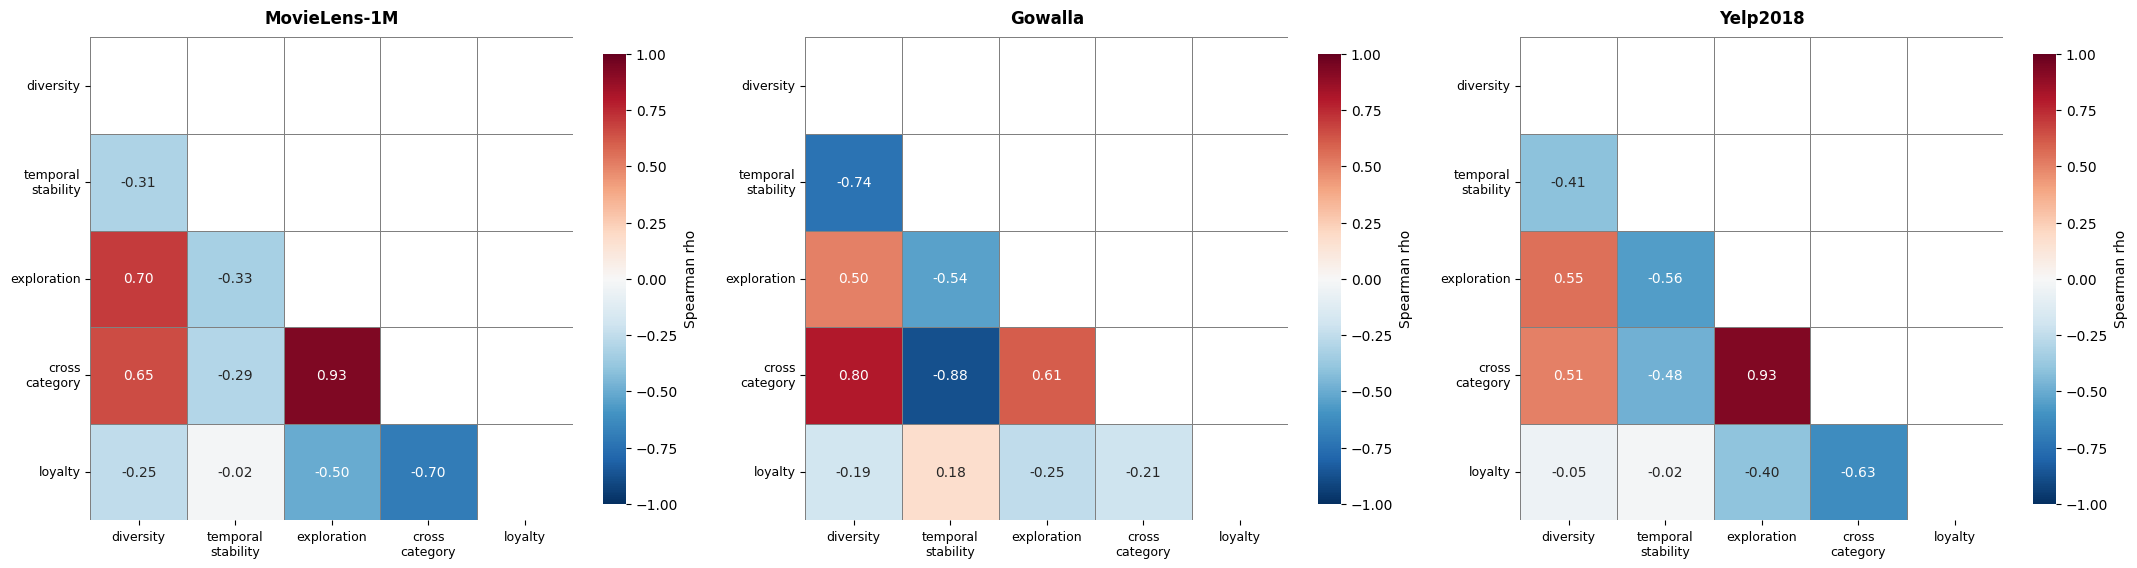

In [8]:
# ============================================================================
# CELL 8 — OPTIONAL: all three heatmaps side by side (one figure for the paper)
# ============================================================================
fig, axes = plt.subplots(1, len(corr_store), figsize=(7.2 * len(corr_store), 6.3))
axes = np.atleast_1d(axes)
for ax, (name, c) in zip(axes, corr_store.items()):
    plot_corr_heatmap(c, name, ax, mask_upper=True)
plt.tight_layout()
plt.savefig('all_datasets_spearman_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()